# Notebook 01 — Build the triage dataset

**Project:** AI-Powered Telemedicine Chatbot for Primary Healthcare Consultation in Kenya
**Goal:** build a labelled dataset that maps a patient's symptom description (free text) to one of four triage levels used by the system:

| Level | Meaning |
|---|---|
| `self-care` | Manage at home (rest, fluids, monitoring) |
| `pharmacy` | Over-the-counter treatment / pharmacist advice |
| `clinic` | Needs assessment, testing or prescription at a health facility |
| `emergency` | Needs urgent care now |

**Sources**
1. **Symptom2Disease** (Kaggle) — ~1,200 natural-language symptom descriptions across 24 conditions. Each condition is mapped to a triage level using a documented rule table (below).
2. **Curated examples** (`data/curated/curated_examples.csv`) — ~300 hand-written examples that fill the gaps in the public data: emergency red flags, minor self-care and pharmacy cases, and **Kiswahili** examples for every level.

**Output:** `data/processed/triage_dataset.csv` (used by Notebook 02), plus figures and tables for the report in `reports/`.

In [1]:
from pathlib import Path
import re

import pandas as pd
import matplotlib.pyplot as plt

# Works whether the notebook is opened from ml/ or ml/notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

RAW_FILE      = ROOT / 'data' / 'raw' / 'Symptom2Disease.csv'
CURATED_FILE  = ROOT / 'data' / 'curated' / 'curated_examples.csv'
PROCESSED_DIR = ROOT / 'data' / 'processed'
REPORTS_DIR   = ROOT / 'reports'
FIGURES_DIR   = REPORTS_DIR / 'figures'

for d in (PROCESSED_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)

TRIAGE_LEVELS = ['self-care', 'pharmacy', 'clinic', 'emergency']
TRIAGE_COLORS = {'self-care': '#2e7d32', 'pharmacy': '#1565c0', 'clinic': '#ef6c00', 'emergency': '#c62828'}

print('Project root :', ROOT)
print('Raw file     :', RAW_FILE.exists())
print('Curated file :', CURATED_FILE.exists())

Project root : C:\Users\thuku\telemedicine-chatbot\ml
Raw file     : True
Curated file : True


## 1. Load the public dataset
The CSV has an unnamed index column, `label` (the condition) and `text` (the patient's description).

In [2]:
raw = pd.read_csv(RAW_FILE)
raw = raw.drop(columns=[c for c in raw.columns if c.lower().startswith('unnamed')])

print('Shape:', raw.shape)
print('Columns:', list(raw.columns))
raw.head()

Shape: (1200, 2)
Columns: ['label', 'text']


,label,text
0,Psoriasis,I have been experiencing a skin rash on my arm...
1,Psoriasis,"My skin has been peeling, especially on my kne..."
2,Psoriasis,I have been experiencing joint pain in my fing...
3,Psoriasis,"There is a silver like dusting on my skin, esp..."
4,Psoriasis,"My nails have small dents or pits in them, and..."


In [3]:
# How many examples per condition?
raw['label'].value_counts().to_frame('examples')

,examples
label,
Psoriasis,50
Varicose Veins,50
Typhoid,50
Chicken pox,50
Impetigo,50
Dengue,50
Fungal infection,50
Common Cold,50
Pneumonia,50


## 2. Clean the text
- Trim and collapse whitespace
- Drop empty rows and exact duplicates (case-insensitive)

In [4]:
def clean_text(s: str) -> str:
    s = str(s).replace('’', "'").replace('‘', "'")
    s = re.sub(r'\s+', ' ', s)
    return s.strip()

before = len(raw)
raw['text'] = raw['text'].map(clean_text)
raw['label'] = raw['label'].map(lambda s: clean_text(s))
raw = raw[raw['text'].str.len() > 0]
raw = raw.loc[~raw['text'].str.lower().duplicated()]
print(f'Rows before: {before}  after cleaning: {len(raw)}  (removed {before - len(raw)})')

Rows before: 1200  after cleaning: 1153  (removed 47)


## 3. Map each condition to a triage level
The public dataset is labelled with **conditions**, not triage levels, so each condition is mapped using the rule below.
The rationale is based on Kenyan primary-care practice (Kenya Essential Package for Health / MoH clinical guidelines):

- **self-care** — mild, self-limiting, no medicine needed
- **pharmacy** — treatable with over-the-counter medicine and pharmacist advice
- **clinic** — needs a clinician: **any fever** (malaria must be confirmed by test in Kenya), prescription-only treatment, chronic disease management, or diagnosis
- **emergency** — none of the 24 conditions is an emergency *by default*; emergency examples come from the curated set

> ⚠️ This mapping is a simplification: a condition can be mild or severe in different patients. This is a stated limitation of the model.

In [5]:
# condition (lower-case) -> (triage level, rationale)
DISEASE_TO_TRIAGE = {
    'common cold':                      ('self-care', 'Self-limiting viral illness; rest and fluids'),
    'acne':                             ('pharmacy',  'OTC topical treatments (e.g. benzoyl peroxide)'),
    'allergy':                          ('pharmacy',  'OTC antihistamines; pharmacist advice'),
    'fungal infection':                 ('pharmacy',  'OTC antifungal creams'),
    'gastroesophageal reflux disease':  ('pharmacy',  'OTC antacids; lifestyle advice'),
    'migraine':                         ('pharmacy',  'OTC analgesics for known recurrent migraine'),
    'dimorphic hemorrhoids':            ('pharmacy',  'OTC haemorrhoid creams; diet advice'),
    'dimorphic hemmorhoids':            ('pharmacy',  'OTC haemorrhoid creams; diet advice'),
    'chicken pox':                      ('clinic',    'Fever with rash needs confirmation; risk in adults'),
    'psoriasis':                        ('clinic',    'Chronic skin disease; prescription treatment'),
    'varicose veins':                   ('clinic',    'Needs assessment; risk of complications'),
    'typhoid':                          ('clinic',    'Needs lab test and prescription antibiotics'),
    'impetigo':                         ('clinic',    'Bacterial skin infection; prescription antibiotics'),
    'dengue':                           ('clinic',    'Fever needs testing; monitoring for warning signs'),
    'pneumonia':                        ('clinic',    'Needs examination and antibiotics'),
    'arthritis':                        ('clinic',    'Chronic condition; diagnosis and management'),
    'bronchial asthma':                 ('clinic',    'Needs diagnosis and prescription inhalers'),
    'hypertension':                     ('clinic',    'Chronic disease; BP monitoring and prescription'),
    'cervical spondylosis':             ('clinic',    'Needs clinical assessment / imaging'),
    'jaundice':                         ('clinic',    'Needs investigation of the cause'),
    'malaria':                          ('clinic',    'Must be confirmed by test (mRDT/microscopy) before treatment'),
    'urinary tract infection':          ('clinic',    'Needs prescription antibiotics'),
    'drug reaction':                    ('clinic',    'Needs review of medication by a clinician'),
    'peptic ulcer disease':             ('clinic',    'Needs diagnosis (H. pylori) and prescription'),
    'diabetes':                         ('clinic',    'Chronic disease; testing and management'),
}

raw['condition_key'] = raw['label'].str.lower().str.strip()
unmapped = sorted(set(raw['condition_key']) - set(DISEASE_TO_TRIAGE))
if unmapped:
    raise ValueError(f'These conditions have no triage mapping, add them to DISEASE_TO_TRIAGE: {unmapped}')
print('All', raw['condition_key'].nunique(), 'conditions mapped ✅')

All 24 conditions mapped ✅


In [6]:
# Mapping table for the report appendix
mapping_table = (
    raw.groupby('label').size().rename('examples').reset_index()
       .assign(triage=lambda d: d['label'].str.lower().map(lambda k: DISEASE_TO_TRIAGE[k][0]),
               rationale=lambda d: d['label'].str.lower().map(lambda k: DISEASE_TO_TRIAGE[k][1]))
       .assign(order=lambda d: d['triage'].map(TRIAGE_LEVELS.index))
       .sort_values(['order', 'label'])
       .drop(columns='order')
       .rename(columns={'label': 'condition'})
       .reset_index(drop=True)
)
mapping_table.to_csv(REPORTS_DIR / 'disease_triage_mapping.csv', index=False)
mapping_table

,condition,examples,triage,rationale
0,Common Cold,49,self-care,Self-limiting viral illness; rest and fluids
1,Acne,46,pharmacy,OTC topical treatments (e.g. benzoyl peroxide)
2,Dimorphic Hemorrhoids,41,pharmacy,OTC haemorrhoid creams; diet advice
3,Fungal infection,50,pharmacy,OTC antifungal creams
4,Migraine,47,pharmacy,OTC analgesics for known recurrent migraine
5,allergy,50,pharmacy,OTC antihistamines; pharmacist advice
6,gastroesophageal reflux disease,48,pharmacy,OTC antacids; lifestyle advice
7,Arthritis,46,clinic,Chronic condition; diagnosis and management
8,Bronchial Asthma,49,clinic,Needs diagnosis and prescription inhalers
9,Cervical spondylosis,49,clinic,Needs clinical assessment / imaging


In [7]:
public = pd.DataFrame({
    'text':      raw['text'],
    'triage':    raw['condition_key'].map(lambda k: DISEASE_TO_TRIAGE[k][0]),
    'language':  'en',
    'source':    'symptom2disease',
    'condition': raw['label'],
})
public['triage'].value_counts().reindex(TRIAGE_LEVELS, fill_value=0).to_frame('examples')

,examples
triage,
self-care,49
pharmacy,282
clinic,822
emergency,0


## 4. Add the curated examples
These fill the gaps in the public data: **emergency red flags** (the public data has none), more **self-care / pharmacy** cases, and **Kiswahili** for all four levels.
They were drafted for this project and reviewed by the developer.

In [8]:
curated = pd.read_csv(CURATED_FILE)
curated['text'] = curated['text'].map(clean_text)
curated['source'] = 'curated'
curated['condition'] = ''

bad = curated.loc[~curated['triage'].isin(TRIAGE_LEVELS)]
assert bad.empty, f'Invalid triage labels in curated file:\n{bad}'

pd.crosstab(curated['triage'], curated['language']).reindex(TRIAGE_LEVELS, fill_value=0)

language,en,sw
triage,,
self-care,60,30
pharmacy,45,25
clinic,10,35
emergency,75,25


## 5. Combine, de-duplicate and shuffle

In [9]:
dataset = pd.concat([public, curated[['text', 'triage', 'language', 'source', 'condition']]], ignore_index=True)

before = len(dataset)
dataset = dataset.loc[~dataset['text'].str.lower().duplicated()]
dataset = dataset.sample(frac=1, random_state=42).reset_index(drop=True)
print(f'Combined: {before}  after de-duplication: {len(dataset)}')

summary = pd.crosstab(dataset['triage'], dataset['source'], margins=True, margins_name='total')
summary = summary.reindex(TRIAGE_LEVELS + ['total'])
summary['% of total'] = (summary['total'] / len(dataset) * 100).round(1)
summary

Combined: 1458  after de-duplication: 1458


source,curated,symptom2disease,total,% of total
triage,,,,
self-care,90,49,139,9.5
pharmacy,70,282,352,24.1
clinic,45,822,867,59.5
emergency,100,0,100,6.9
total,305,1153,1458,100.0


## 6. Explore the final dataset

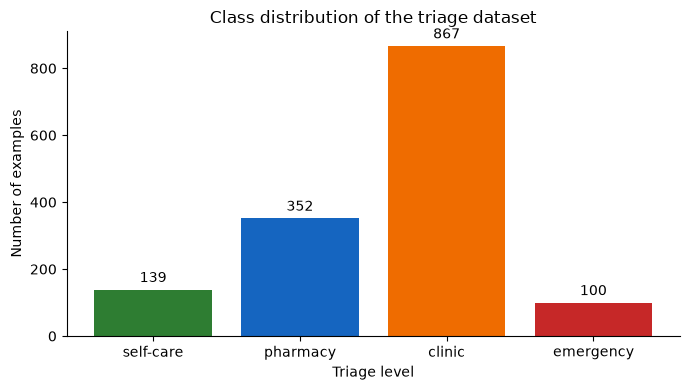

In [10]:
counts = dataset['triage'].value_counts().reindex(TRIAGE_LEVELS)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(counts.index, counts.values, color=[TRIAGE_COLORS[t] for t in counts.index])
ax.bar_label(bars, padding=3)
ax.set_title('Class distribution of the triage dataset')
ax.set_xlabel('Triage level')
ax.set_ylabel('Number of examples')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'class_distribution.png', dpi=200)
plt.show()

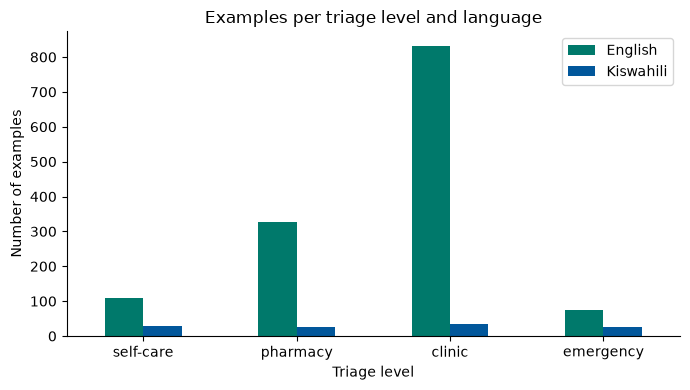

language,en,sw
triage,,
self-care,109,30
pharmacy,327,25
clinic,832,35
emergency,75,25


In [11]:
lang = pd.crosstab(dataset['triage'], dataset['language']).reindex(TRIAGE_LEVELS)

ax = lang.plot(kind='bar', figsize=(7, 4), color=['#00796b', '#01579b'], rot=0)
ax.set_title('Examples per triage level and language')
ax.set_xlabel('Triage level')
ax.set_ylabel('Number of examples')
ax.legend(['English', 'Kiswahili'])
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'language_distribution.png', dpi=200)
plt.show()
lang

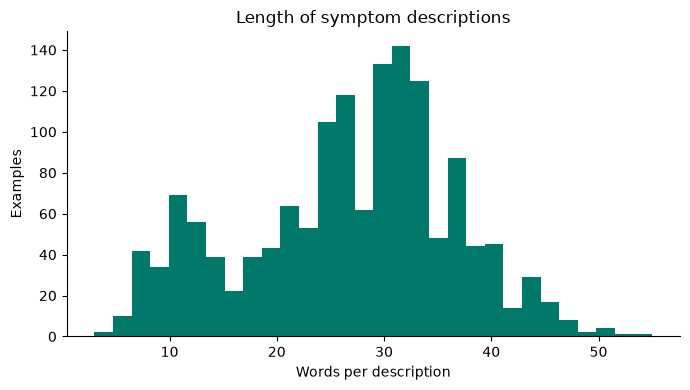

,count,mean,std,min,25%,50%,75%,max
triage,,,,,,,,
self-care,139.0,20.4,13.7,4.0,9.0,13.0,35.0,53.0
pharmacy,352.0,26.9,10.7,5.0,21.0,27.0,34.0,50.0
clinic,867.0,29.1,7.4,5.0,25.0,30.0,34.0,55.0
emergency,100.0,14.4,3.7,3.0,12.0,14.0,17.0,21.0


In [12]:
dataset['words'] = dataset['text'].str.split().str.len()

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(dataset['words'], bins=30, color='#00796b')
ax.set_title('Length of symptom descriptions')
ax.set_xlabel('Words per description')
ax.set_ylabel('Examples')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'text_length.png', dpi=200)
plt.show()

dataset.groupby('triage')['words'].describe().reindex(TRIAGE_LEVELS).round(1)

In [13]:
# A few random examples from each level
for level in TRIAGE_LEVELS:
    print(f'\n=== {level.upper()} ===')
    for t in dataset.loc[dataset['triage'] == level, 'text'].sample(3, random_state=1):
        print(' •', t)


=== SELF-CARE ===
 • I've been quite exhausted and ill. My throat has been quite painful, and I've had a fairly nasty cough. I've got a lot of chills and a pretty high temperature. Simply put, I feel really run down and feeble.
 • I have a small splinter in my finger.
 • I have a mild headache after drinking alcohol last night.

=== PHARMACY ===
 • I've been struggling with a really nasty rash on my skin lately. It's covered in blackheads and pimples that are packed with pus. My skin has also been really scurrying.
 • It's incredibly difficult for me to use the restroom, and when I do, it hurts a lot. My stools have been bloody, and my butt has been hurting. My anus has also been quite itching and aggravated.
 • I have trouble breathing and get short of breath. I have a dry, hacking cough, itchy eyes, and swelling all over my face and body.

=== CLINIC ===
 • The skin around the veins on my legs is dry and flaky, causing discomfort and irritation. I am also starting to get frequent cr

## 7. Save

In [14]:
out = PROCESSED_DIR / 'triage_dataset.csv'
dataset.drop(columns=['words']).to_csv(out, index=False)
print('Saved', len(dataset), 'rows to', out)
print('Figures saved to', FIGURES_DIR)

Saved 1458 rows to C:\Users\thuku\telemedicine-chatbot\ml\data\processed\triage_dataset.csv
Figures saved to C:\Users\thuku\telemedicine-chatbot\ml\reports\figures


## Observations (fill in for the report)
- The dataset is **imbalanced**: `clinic` is the largest class because most public conditions need a clinician. Notebook 02 handles this with **class weights** and reports **macro-F1** and **emergency recall** rather than accuracy alone.
- **Emergency** and **Kiswahili** examples come only from the curated set, so performance on them should be interpreted with care (smaller sample, single author).
- Limitation: triage labels for the public data are derived from the condition, not assigned by a clinician per example.